# Notebook 3. Did we call the event

**Predicting Flash Floods in Working Landscapes**, Module 3, Event based evaluation and forecast skill
CUAHSI Water Science Exchange 2026, University of Missouri, Saturday November 14, 2026
Humberto Vergara and Mohamed Abdelkader, University of Iowa, IIHR Hydroscience and Engineering

## What this notebook does

For every day of the five year window we now have a forecast probability that flow exceeds the flood threshold, and the observed yes or no outcome. The first verification question is the one an emergency manager asks. Did the forecast call the flood, yes or no? That is categorical verification. It rests on one small table, the two by two contingency table, from which a family of scores follows.

Module objective covered here. Verify event forecasts with the contingency table, categorical scores and the ROC curve.

| Step | What we do |
|---|---|
| 1 | Rebuild the forecast from Notebooks 1 and 2 |
| 2 | Count hits, misses, false alarms and correct negatives |
| 3 | Compute POD, FAR, POFD and CSI, and keep FAR and POFD apart |
| 4 | Turn a probability into a decision with a threshold |
| 5 | Trace the ROC curve and read its area |
| 6 | Summarise everything on the performance diagram |
| 7 | Your turn |

## 0. Setup

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/AHWALab/Water-Science-Exchange-Workshop.git"
BRANCH = "module-3-evaluation"

# In Colab the helper files are not here yet. Copy the branch (public, no account needed).
if not Path("hymod_tools.py").exists():
    if not Path("Water-Science-Exchange-Workshop").is_dir():
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "-b", BRANCH, REPO_URL, "Water-Science-Exchange-Workshop"], check=True)
    os.chdir("Water-Science-Exchange-Workshop/notebooks")
sys.path.insert(0, os.getcwd())
print("Working folder:", os.getcwd())

Working folder: /home/claude/wse/notebooks


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import hymod_tools as h
import nb_style
from nb_style import PALETTE
nb_style.set_style()

## 1. Rebuild the forecast

Same seed, same ensemble, same probabilities as Notebook 2.

In [3]:
# Step 1. Data, window, threshold.
PP, PET, QQ = h.load_leaf_river("LeafCatch.dat")
N_EVAL = 365 * 5
Qobs = QQ[:N_EVAL]
flood_th = h.flood_threshold(QQ, fraction=0.25)

# Step 2. The ensemble and the control run.
ensemble, _ = h.generate_ensemble(PP, PET, N_EVAL, Nens=100, seed=7)
Nens = ensemble.shape[0]
Qctrl = h.hymod01(PP[:N_EVAL], PET[:N_EVAL], h.CONTROL_PARS)["Q"]

In [4]:
# Step 3. Observed events, forecast probabilities, base rate.
obs_events = (Qobs >= flood_th).astype(int)
prob_exceed = (ensemble >= flood_th).mean(axis=0)
climatology = obs_events.mean()
print(f"days {N_EVAL}, events {obs_events.sum()}, base rate {climatology:.3f}, threshold {flood_th:.2f} mm/day")

days 1825, events 115, base rate 0.063, threshold 5.00 mm/day


## 2. The contingency table

Compare a binary forecast with the binary observation and count the four outcomes.

| | Observed event | Observed no event |
|---|---|---|
| Forecast event | Hits (H) | False alarms (F) |
| Forecast no event | Misses (M) | Correct negatives (C) |

A miss is the dangerous cell, an unwarned flood. A false alarm is the cry wolf cell. Correct negatives are good and usually the most common.

In [5]:
def contingency_table(forecast_event, observed_event):
    """Count H, M, F, C for two arrays of 0 and 1."""
    f = np.asarray(forecast_event).astype(bool)
    o = np.asarray(observed_event).astype(bool)
    H = int(np.sum(f & o))        # forecast yes, observed yes
    M = int(np.sum(~f & o))       # forecast no, observed yes, the missed event
    F = int(np.sum(f & ~o))       # forecast yes, observed no, the false alarm
    C = int(np.sum(~f & ~o))      # forecast no, observed no
    return {"H": H, "M": M, "F": F, "C": C}

In [6]:
# First example. The control run as a deterministic forecast, an event whenever it exceeds the threshold.
# (The ensemble mean is too smooth to reach the threshold at all. Averaging a wide ensemble erases the peaks.)
control_forecast = (Qctrl >= flood_th).astype(int)
ct = contingency_table(control_forecast, obs_events)

print("control run against the observations")
print(f"  hits H = {ct['H']:4d}   misses M = {ct['M']:4d}")
print(f"  false alarms F = {ct['F']:4d}   correct negatives C = {ct['C']:4d}")
print(f"  check: H + M + F + C = {sum(ct.values())}, should be {N_EVAL}")

control run against the observations
  hits H =   95   misses M =   20
  false alarms F =   70   correct negatives C = 1640
  check: H + M + F + C = 1825, should be 1825


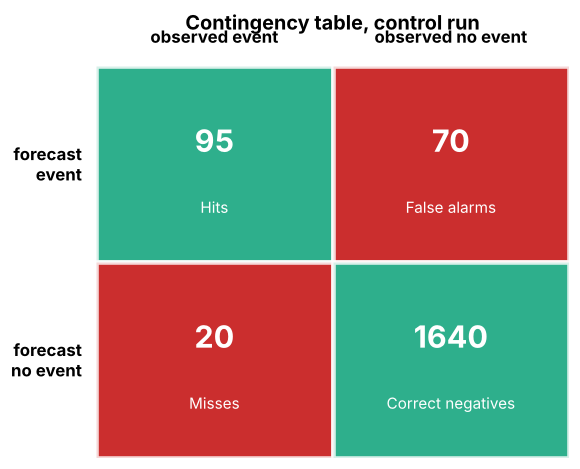

In [7]:
def plot_contingency(ct, title):
    """Colour the four cells. Green on the diagonal is good, red off the diagonal is bad."""
    M = np.array([[ct["H"], ct["F"]], [ct["M"], ct["C"]]])
    colors = np.array([[PALETTE["accent"], PALETTE["threshold"]], [PALETTE["threshold"], PALETTE["accent"]]])
    labels = [["Hits", "False alarms"], ["Misses", "Correct negatives"]]
    fig, ax = plt.subplots(figsize=(5.4, 4.4)); ax.set_xlim(0, 2); ax.set_ylim(0, 2); ax.axis("off")
    for i in range(2):
        for j in range(2):
            ax.add_patch(plt.Rectangle((j, 1 - i), 1, 1, fc=colors[i, j], ec="white", lw=3, alpha=0.82))
            ax.text(j + 0.5, 1 - i + 0.62, f"{M[i, j]}", ha="center", va="center", fontsize=20, fontweight="bold", color="white")
            ax.text(j + 0.5, 1 - i + 0.28, labels[i][j], ha="center", va="center", fontsize=10, color="white")
    ax.text(0.5, 2.12, "observed event", ha="center", fontweight="bold")
    ax.text(1.5, 2.12, "observed no event", ha="center", fontweight="bold")
    ax.text(-0.06, 1.5, "forecast\nevent", ha="right", va="center", fontweight="bold")
    ax.text(-0.06, 0.5, "forecast\nno event", ha="right", va="center", fontweight="bold")
    ax.set_title(title, pad=24); plt.tight_layout(); plt.show()

plot_contingency(ct, "Contingency table, control run")

## 3. Categorical scores

Four scores come out of the four counts. Watch the denominators, they are what separates the scores.

$$ \text{POD} = \frac{H}{H+M}, \qquad \text{FAR} = \frac{F}{H+F}, \qquad \text{POFD} = \frac{F}{F+C}, \qquad \text{CSI} = \frac{H}{H+M+F}. $$

- POD, probability of detection or hit rate. Of the events that happened, the fraction we caught. 1 is perfect.
- FAR, false alarm ratio. Of the events we forecast, the fraction that did not happen. 0 is perfect.
- POFD, probability of false detection or false alarm rate. Of the non events, the fraction we flagged. 0 is perfect. This is the x axis of the ROC curve.
- CSI, critical success index. Hits over everything forecast or observed, ignoring the easy correct negatives. 1 is perfect.

FAR and POFD are not the same thing. FAR divides by forecast events, POFD by observed non events. Mixing them up is the most common verification error, and it changes the ROC curve completely.

In [8]:
def categorical_scores(ct):
    """POD, FAR, POFD, CSI, success ratio and frequency bias from one table."""
    H, M, F, C = ct["H"], ct["M"], ct["F"], ct["C"]
    def safe(num, den):
        return num / den if den > 0 else np.nan
    return {"POD": safe(H, H + M),         # hit rate, 1 is best
            "FAR": safe(F, H + F),         # false alarm ratio, 0 is best
            "POFD": safe(F, F + C),        # false alarm rate, 0 is best, ROC x axis
            "CSI": safe(H, H + M + F),     # threat score, 1 is best
            "SR": safe(H, H + F),          # success ratio, 1 minus FAR
            "BIAS": safe(H + F, H + M)}    # frequency bias, 1 means as many forecasts as events

In [9]:
sc = categorical_scores(ct)
print("control run")
for k in ["POD", "FAR", "POFD", "CSI", "SR", "BIAS"]:
    print(f"   {k:<5} = {sc[k]:.3f}")
print(f"\nreading it: we detect {100 * sc['POD']:.0f} percent of flood days, "
      f"{100 * sc['FAR']:.0f} percent of our warnings are false alarms, "
      f"frequency bias {sc['BIAS']:.2f} ({'over' if sc['BIAS'] > 1 else 'under'} forecasting events)")

control run
   POD   = 0.826
   FAR   = 0.424
   POFD  = 0.041
   CSI   = 0.514
   SR    = 0.576
   BIAS  = 1.435

reading it: we detect 83 percent of flood days, 42 percent of our warnings are false alarms, frequency bias 1.43 (over forecasting events)


## 4. From probability to decision

A probabilistic forecast does not act on its own. A user converts it into yes or no with a probability threshold $p^*$, warn when $p_t \ge p^*$. A cautious agency uses a low $p^*$ and accepts false alarms to avoid misses. A cost sensitive user uses a high $p^*$. Every choice gives its own contingency table.

In [10]:
# This ensemble runs dry (Notebook 2, section 5), so its probabilities never pass 15 percent.
# Useful decision thresholds are therefore low. Try three of them.
print(f"largest forecast probability on any day {prob_exceed.max():.2f}\n")
for p_star in [0.02, 0.05, 0.10]:
    forecast = (prob_exceed >= p_star).astype(int)           # the decision rule
    s = categorical_scores(contingency_table(forecast, obs_events))
    print(f"p* = {p_star:.2f}:  POD = {s['POD']:.2f}  POFD = {s['POFD']:.2f}  FAR = {s['FAR']:.2f}  CSI = {s['CSI']:.2f}")
print("\nlower p* means more warnings, higher POD and also higher POFD and FAR. The ROC curve traces that trade off.")

largest forecast probability on any day 0.15

p* = 0.02:  POD = 0.51  POFD = 0.12  FAR = 0.77  CSI = 0.19
p* = 0.05:  POD = 0.27  POFD = 0.04  FAR = 0.69  CSI = 0.17
p* = 0.10:  POD = 0.10  POFD = 0.01  FAR = 0.54  CSI = 0.09

lower p* means more warnings, higher POD and also higher POFD and FAR. The ROC curve traces that trade off.


## 5. The ROC curve

The relative operating characteristic sweeps $p^*$ from 1 down to 0 and plots POD against POFD at each step. It answers one question. As we accept more false alarms, how many more real events do we catch?

- The diagonal POD = POFD is the no skill line, a random forecast.
- A curve that bows toward the top left corner has skill.
- The area under the curve, AUC, summarises it. 0.5 is no skill, 1.0 is perfect.

The x axis is POFD, F over F plus C, not the false alarm ratio.

In [11]:
# Step 1. Sweep the decision threshold and record POD, POFD and FAR at each value.
p_thresholds = np.linspace(0, 1, 41)
roc_pod, roc_pofd, roc_far = [], [], []
for p_star in p_thresholds:
    s = categorical_scores(contingency_table((prob_exceed >= p_star).astype(int), obs_events))
    roc_pod.append(np.nan_to_num(s["POD"]))
    roc_pofd.append(np.nan_to_num(s["POFD"]))
    roc_far.append(np.nan_to_num(s["FAR"]))
roc_pod, roc_pofd, roc_far = map(np.array, (roc_pod, roc_pofd, roc_far))

# Step 2. Area under the curve by the trapezoidal rule, with POFD sorted in increasing order.
order = np.argsort(roc_pofd)
auc = np.trapezoid(roc_pod[order], roc_pofd[order])
print(f"ROC area under the curve = {auc:.3f}")

ROC area under the curve = 0.682


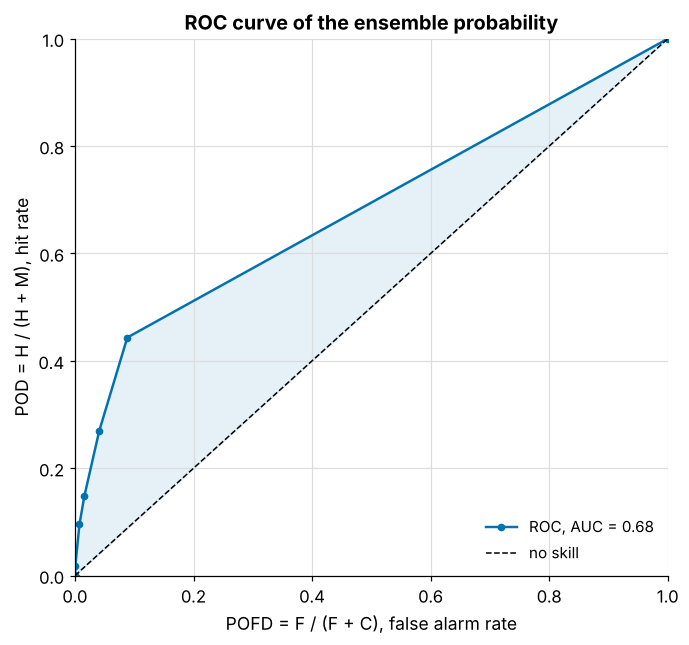

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.plot(roc_pofd, roc_pod, "-o", color=PALETTE["control"], ms=4, label=f"ROC, AUC = {auc:.2f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="no skill")
ax.fill_between(roc_pofd[order], roc_pofd[order], roc_pod[order], color=PALETTE["control"], alpha=0.10)
ax.set_xlabel("POFD = F / (F + C), false alarm rate")
ax.set_ylabel("POD = H / (H + M), hit rate")
ax.set_title("ROC curve of the ensemble probability"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

Why the axis matters. FAR depends on the base rate. Floods are rare, most days are non events, so F over H plus F and F over F plus C differ enormously. A curve drawn with FAR cannot be compared with the no skill diagonal. Always check which false alarm quantity a figure uses.

## 6. The performance diagram

The performance diagram (Roebber 2009) packs four scores into one picture. POD against success ratio (1 minus FAR), with CSI as curved contours and frequency bias as straight dashed lines. The perfect forecast sits in the top right corner. Each point is one decision threshold $p^*$.

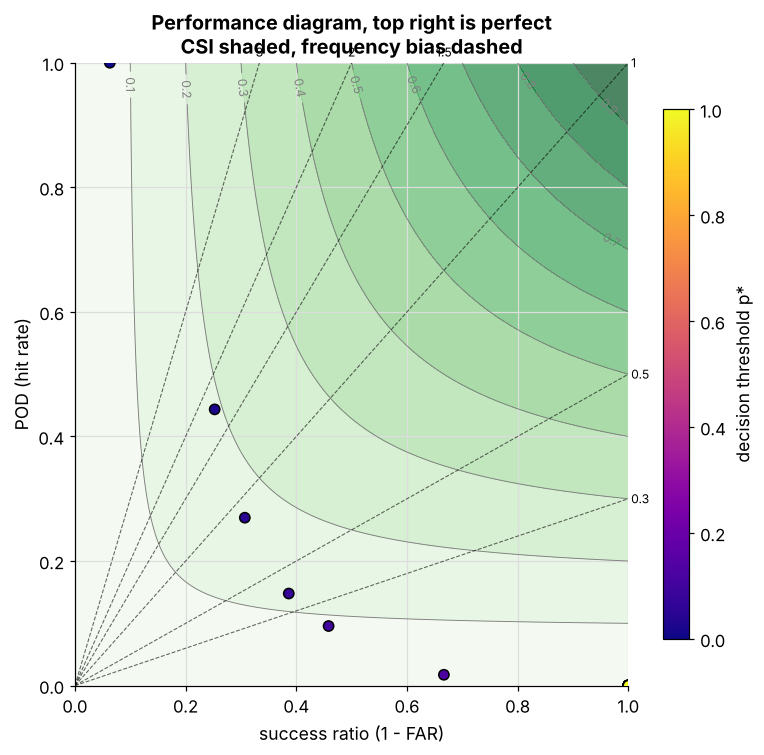

In [13]:
fig, ax = plt.subplots(figsize=(7.2, 7))

# Background, CSI contours and frequency bias lines.
grid = np.linspace(0.001, 1, 200); SRg, PODg = np.meshgrid(grid, grid)
CSIg = 1.0 / (1.0 / SRg + 1.0 / PODg - 1.0)
cs = ax.contourf(SRg, PODg, CSIg, levels=np.arange(0, 1.01, 0.1), cmap="Greens", alpha=0.7)
cl = ax.contour(SRg, PODg, CSIg, levels=np.arange(0.1, 1.0, 0.1), colors="grey", linewidths=0.6)
ax.clabel(cl, fmt="%.1f", fontsize=8)
for b in [0.3, 0.5, 1.0, 1.5, 2.0, 3.0]:                  # frequency bias rays, POD = b x SR
    ax.plot([0, 1], [0, b], "k--", lw=0.7, alpha=0.6)
    if b <= 1:
        ax.text(1.005, b, f"{b:g}", fontsize=8, va="center")
    else:
        ax.text(1.0 / b, 1.01, f"{b:g}", fontsize=8, ha="center")

# The operating points, one per decision threshold, coloured by p*.
sr_pts = 1 - roc_far
sccol = ax.scatter(sr_pts, roc_pod, c=p_thresholds, cmap="plasma", s=45, edgecolor="k", zorder=5)
plt.colorbar(sccol, label="decision threshold p*", shrink=0.85)
ax.set_xlabel("success ratio (1 - FAR)"); ax.set_ylabel("POD (hit rate)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Performance diagram, top right is perfect\nCSI shaded, frequency bias dashed")
plt.tight_layout(); plt.show()

## 7. Your turn

Which decision threshold gives the best CSI? Find it and report the full set of scores at that threshold.

In [14]:
#################### Your Code Goes Here #########################
# Step 1. CSI at every threshold in p_thresholds (categorical_scores and contingency_table).
csi_values = []
for p_star in p_thresholds:
    s = categorical_scores(contingency_table((prob_exceed >= p_star).astype(int), obs_events))
    csi_values.append(s["CSI"])
csi_values = np.array(csi_values)

# Step 2. The threshold with the largest CSI (np.nanargmax).
best = int(np.nanargmax(csi_values))
p_best = p_thresholds[best]

# Step 3. Print that threshold and its POD, FAR, POFD, CSI and frequency bias.
s = categorical_scores(contingency_table((prob_exceed >= p_best).astype(int), obs_events))
print(f"best CSI at p* = {p_best:.3f}")
for k in ["POD", "FAR", "POFD", "CSI", "BIAS"]:
    print(f"   {k:<5} = {s[k]:.3f}")
###################################################################

best CSI at p* = 0.025
   POD   = 0.443
   FAR   = 0.748
   POFD  = 0.088
   CSI   = 0.192
   BIAS  = 1.757


Questions for the group

1. Is the threshold with the best CSI the one a flood warning office should use? What does the frequency bias say at that point?
2. The ensemble of Notebook 2 under predicts rain on average. Where would you expect its points to sit on the performance diagram, and is that what you see?

## Recap

- The contingency table underlies all categorical verification.
- POD, FAR, POFD and CSI answer different questions. FAR and POFD are not interchangeable.
- A decision threshold turns a probability into a warning. Sweeping it traces the ROC curve, summarised by the AUC.
- The performance diagram shows POD, success ratio, CSI and frequency bias together.

Categorical scores judge whether we got the event right, but they throw away most of the probability information. Notebook 4 keeps the full probabilities and asks whether they are reliable and sharp.

## References and credits

- Wilks, D. S., 2019. Statistical Methods in the Atmospheric Sciences, 4th edition, Elsevier. Chapter 9, forecast verification.
- Roebber, P. J., 2009. Visualizing multiple measures of forecast quality. Weather and Forecasting, 24, 601 to 608.
- Mason, I., 1982. A model for assessment of weather forecasts. Australian Meteorological Magazine, 30, 291 to 303. The ROC curve in meteorology.
- Adapted from the Ensemble Forecast Evaluation series prepared by Humberto Vergara and Mohamed Abdelkader for the CIROH Summer Institute 2026.